# Diverging Column (over time)

**Family:** Deviation &nbsp;|&nbsp; **Library:** matplotlib / seaborn

> *Deviation:* Emphasise variations (+/-) from a fixed reference point: zero, a target, or an average.

## Design purpose

Vertical bars rising from or falling below zero, one per time period. Each discrete period's positive or negative result stands on its own.

## When to use

- Show discrete periods with signed results (monthly net cash flow, quarterly earnings surprise)
- Count the positive and negative periods

## Avoid when

- The data is continuous and dense (use a surplus/deficit line)
- There are more than ~60 periods

## Alternatives

- Surplus/deficit filled line
- Waterfall chart (to show the cumulative effect)

## Example

Monthly net cash flow of a small business over two years.

### Setup

In [1]:
%matplotlib inline
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

# Library style: categorical colors in fixed order, recessive axes, hairline grid.
PALETTE = ["#2a78d6", "#eb6834", "#1baf7a", "#eda100",
           "#e87ba4", "#008300", "#6250d6", "#e34948"]
SEQ_CMAP = "Blues"      # sequential: one hue, light -> dark
DIV_CMAP = "RdBu_r"     # diverging: two opposite hues, neutral midpoint
GRAY = "#b8b7b1"        # de-emphasised marks
plt.rcParams.update({
    "figure.figsize": (8, 4.8), "figure.dpi": 110, "figure.facecolor": "#fcfcfb",
    "axes.facecolor": "#fcfcfb", "axes.edgecolor": "#c9c8c3", "axes.linewidth": 0.8,
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "grid.color": "#e6e5e1", "grid.linewidth": 0.6, "axes.axisbelow": True,
    "axes.prop_cycle": plt.cycler(color=PALETTE),
    "axes.titlesize": 13, "axes.titleweight": "bold", "axes.titlelocation": "left",
    "axes.labelcolor": "#52514e", "xtick.color": "#52514e", "ytick.color": "#52514e",
    "text.color": "#0b0b0b", "font.size": 10, "lines.linewidth": 2,
    "legend.frameon": False,
})

### Data

In [2]:
rng = np.random.default_rng(5)
months = pd.period_range("2023-01", periods=24, freq="M")
df = pd.DataFrame({"month": months.strftime("%b %y"),
                   "net_cash_k": (rng.normal(4, 12, 24)).round(1)})
df.head()

,month,net_cash_k
0,Jan 23,-5.6
1,Feb 23,-11.9
2,Mar 23,1.0
3,Apr 23,9.0
4,May 23,17.6


### Plot

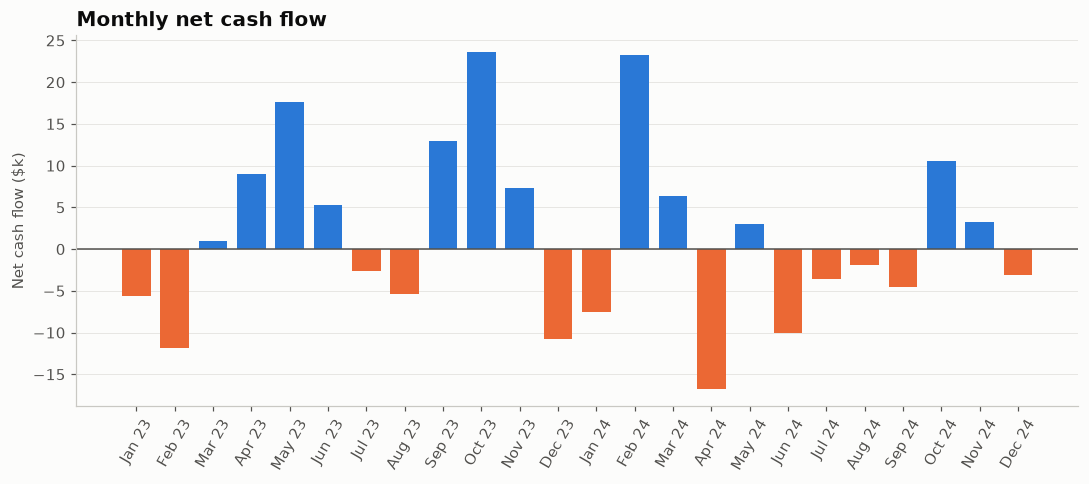

In [3]:
fig, ax = plt.subplots(figsize=(10, 4.5))
colors = np.where(df["net_cash_k"] >= 0, PALETTE[0], PALETTE[1])
ax.bar(df["month"], df["net_cash_k"], color=colors, width=0.75)
ax.axhline(0, color="#52514e", linewidth=1)
ax.set_ylabel("Net cash flow ($k)")
ax.set_title("Monthly net cash flow")
ax.tick_params(axis="x", rotation=60)
ax.grid(axis="x", visible=False)
fig.tight_layout()
plt.show()

---
Standalone script: [`diverging_column_time.py`](diverging_column_time.py) &nbsp;·&nbsp; [Catalogue](../../README.md) &nbsp;·&nbsp; [Gallery](../../gallery/index.html)